# Baseline: Bag of Words + regresja logistyczna (spam w klasie negatywnej)

Wariant `spam_0`: wykrywamy tylko phishing, więc spam należy do klasy negatywnej (etykieta `label_spam_0`).

- **Model:** `CountVectorizer` i `LogisticRegression` z ustawieniami domyślnymi, bez doboru hiperparametrów. Zmieniona jest tylko
  liczba iteracji, żeby solver zbiegł.
- **Podział:** 60% train, 30% val, 10% test na poziomie klastrów, taki sam we wszystkich eksperymentach.
- **Próg:** na zbiorze walidacyjnym, największy recall przy FPR nie większym niż 1%. FPR jest ważony odwrotnością rozmiaru
  klastra, żeby pojedynczy szablon wiadomości nie decydował o progu.
- **Ocena:** zbiór testowy ID i cały korpus OOD, a także każde źródło osobno.

In [ ]:
import sys
import time
from pathlib import Path
import pandas as pd
from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "notebooks"))
from experiment_utils import (
    ID_SOURCES, OOD_SOURCES, TARGET_FPR, corpus_metrics, load_corpora, plot_confusion_matrices, plot_curves, threshold_at_fpr,
)

EXPERIMENT = "bow_lr_spam_0"
LABEL = "label_spam_0"
RESULTS = ROOT / "results" / EXPERIMENT
TABLES, FIGURES = RESULTS / "tables", RESULTS / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200, "display.max_columns", 50, "display.float_format", "{:.4f}".format)

## Dane i podział

In [2]:
in_domain, out_of_domain = load_corpora()
train, val, test = (in_domain[in_domain.split == name] for name in ("train", "val", "test"))
assert not set(train.cluster) & set(val.cluster) and not set(train.cluster) & set(test.cluster) and not set(val.cluster) & set(test.cluster)

split_summary = pd.crosstab([in_domain.source, in_domain.kind], in_domain.split)[["train", "val", "test"]]
split_summary.loc[("razem", ""), :] = split_summary.sum()
split_summary = split_summary.astype(int)
split_summary.to_csv(TABLES / "split_summary.csv")
display(split_summary)
print("Udział zbiorów:", (in_domain.split.value_counts(normalize=True) * 100).round(2).to_dict())

split              train    val   test
source   kind                         
nazario  phishing   5594   2666    918
nigerian phishing   1969    936    335
trec05   ham       19225   9603   3198
         spam      12965   6669   2188
trec06   ham        7346   3671   1221
         spam       2258   1116    361
trec07   ham       14474   7241   2419
         spam      16848   8818   2430
razem              80679  40720  13070

Udział zbiorów: {'train': 60.0, 'val': 30.28, 'test': 9.72}


## Uczenie

In [3]:
start = time.perf_counter()
vectorizer = CountVectorizer()
features_train = vectorizer.fit_transform(train.text)
model = LogisticRegression(max_iter=2000)
model.fit(features_train, train[LABEL])
training_seconds = time.perf_counter() - start
assert model.n_iter_[0] < model.max_iter, "Solver nie zbiegł"
print(f"Słownik: {len(vectorizer.vocabulary_)} tokenów, iteracje: {model.n_iter_[0]}, czas uczenia: {training_seconds:.1f} s")


def score(frame):
    return model.predict_proba(vectorizer.transform(frame.text))[:, 1]

Słownik: 325755 tokenów, iteracje: 384, czas uczenia: 50.3 s


## Dobór progu na zbiorze walidacyjnym

In [4]:
threshold_result = threshold_at_fpr(val[LABEL], score(val), val.cluster)
threshold = threshold_result["próg"]
threshold_table = pd.DataFrame([{
    "docelowy_fpr": TARGET_FPR, **threshold_result,
    "rozmiar_słownika": len(vectorizer.vocabulary_), "czas_uczenia_s": training_seconds,
}])
threshold_table.to_csv(TABLES / "threshold.csv", index=False)
display(threshold_table)

,docelowy_fpr,próg,fpr_ważony_val,fpr_val,recall_val,rozmiar_słownika,czas_uczenia_s
0,0.0100,0.3823,0.0100,0.0202,0.8745,325755,50.2931


## Metryki dla ID i OOD

In [5]:
test_scores, ood_scores = score(test), score(out_of_domain)
corpus_sets = {"ID": (test[LABEL], test_scores), "OOD": (out_of_domain[LABEL], ood_scores)}
metrics = corpus_metrics(corpus_sets, threshold)
metrics.to_csv(TABLES / "metrics.csv", index_label="korpus")
display(metrics)

,n,positives,accuracy,recall,f1,precision,roc_auc,aucpr,fpr
ID,13070.0000,1253.0000,0.9581,0.8204,0.7896,0.7609,0.9654,0.8482,0.0273
OOD,6124.0000,4987.0000,0.6065,0.6549,0.7305,0.8258,0.5764,0.8697,0.6060


## Metryki według źródła

Puste wartości oznaczają metrykę, której nie da się policzyć dla jednej klasy, np. FPR dla Nazario, które ma tylko phishing.

In [6]:
source_sets = {
    name: (test.loc[test.source == name, LABEL], test_scores[(test.source == name).to_numpy()]) for name in ID_SOURCES
} | {
    name: (out_of_domain.loc[out_of_domain.source == name, LABEL], ood_scores[(out_of_domain.source == name).to_numpy()])
    for name in OOD_SOURCES
}
metrics_by_source = corpus_metrics(source_sets, threshold)
metrics_by_source.to_csv(TABLES / "metrics_by_source.csv", index_label="source")
display(metrics_by_source)

,n,positives,accuracy,recall,f1,precision,roc_auc,aucpr,fpr
nazario,918.0000,918.0000,0.8758,0.8758,0.9338,1.0000,NaN,NaN,NaN
nigerian,335.0000,335.0000,0.6687,0.6687,0.8014,1.0000,NaN,NaN,NaN
trec05,5386.0000,0.0000,0.9753,NaN,0.0000,0.0000,NaN,NaN,0.0247
trec06,1582.0000,0.0000,0.9861,NaN,0.0000,0.0000,NaN,NaN,0.0139
trec07,4849.0000,0.0000,0.9654,NaN,0.0000,0.0000,NaN,NaN,0.0346
ferb,5601.0000,4707.0000,0.5954,0.6554,0.7314,0.8273,0.5126,0.8714,0.7204
kd10000,60.0000,55.0000,0.6000,0.5636,0.7209,1.0000,0.9891,0.9990,0.0000
nebulon,145.0000,69.0000,0.7034,0.6087,0.6614,0.7241,0.7815,0.7349,0.2105
zeroday,318.0000,156.0000,0.7579,0.6923,0.7372,0.7883,0.8183,0.8599,0.1790


## Macierze pomyłek i krzywe

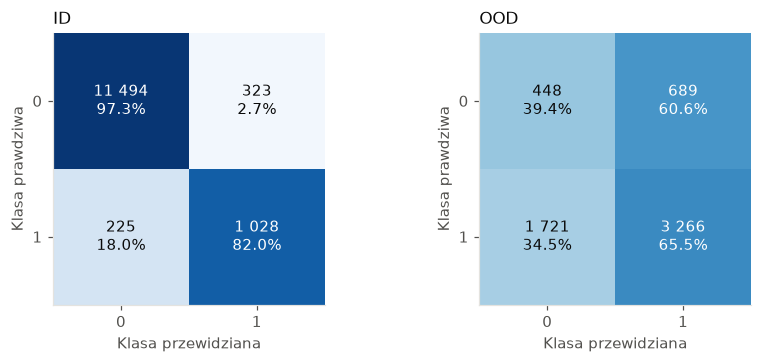

,przewidziane 0,przewidziane 1
prawdziwe 0,11494,323
prawdziwe 1,225,1028


,przewidziane 0,przewidziane 1
prawdziwe 0,448,689
prawdziwe 1,1721,3266


In [7]:
matrices = plot_confusion_matrices(corpus_sets, threshold, FIGURES / "confusion_matrices.pdf")
for name, matrix in matrices.items():
    matrix.to_csv(TABLES / f"confusion_matrix_{name.lower()}.csv")
    display(matrix)

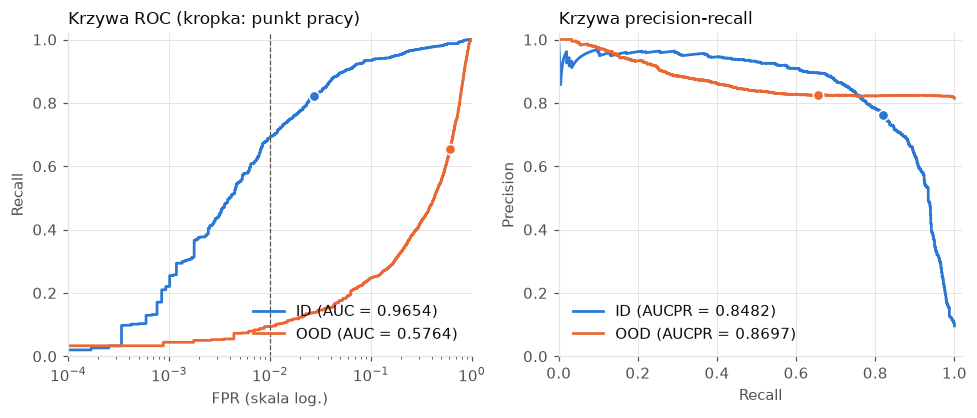

In [8]:
plot_curves(corpus_sets, threshold, FIGURES / "roc_pr_curves.pdf")